<a href="https://www.kaggle.com/code/yumahazzayuditama/3-24060124120035-praktikum-ml?scriptVersionId=368835628" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

**Nama: Yuma Hazza Yuditama** <br>
**NIM: 24060124120035** <br>
**Lab: C1** <br>
**Materi: Klasifikasi Churn Customer** <br>

# Latihan

In [1]:

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

from sklearn.ensemble import (
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

1. Load ulang dataset Churn Modelling dengan nama variabel df_latihan!
   -

In [2]:
DATA_PATH_LATIHAN = (
    "/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv"
    if os.path.exists("/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv")
    else "Churn_Modelling.csv"
)

df_latihan = pd.read_csv(DATA_PATH_LATIHAN)

print("Ukuran dataset df_latihan (baris, kolom):", df_latihan.shape)
display(df_latihan.head())

print("\n" + "=" * 50)
print("Informasi Struktur Dataset (df_latihan):")
display(df_latihan.info())

print("\n" + "=" * 50)
print("\nJumlah baris duplikat:", df_latihan.duplicated().sum())
print("Jumlah missing value per kolom:")
display(df_latihan.isna().sum().to_frame("missing_value"))

Ukuran dataset df_latihan (baris, kolom): (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Informasi Struktur Dataset (df_latihan):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


None



Jumlah baris duplikat: 0
Jumlah missing value per kolom:


,missing_value
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


2. Lakukan feature selection dan data splitting dengan proporsi 70:30.
   -

In [3]:
TARGET_LATIHAN = "Exited"

irrelevant_columns = ["RowNumber", "CustomerId", "Surname"]
irrelevant_columns = [col for col in irrelevant_columns if col in df_latihan.columns]

X_latihan = df_latihan.drop(columns=irrelevant_columns + [TARGET_LATIHAN])
y_latihan = df_latihan[TARGET_LATIHAN].astype(int)

print("Fitur prediktif yang terpilih (10 fitur):")
print(X_latihan.columns.tolist())
print(f"Dimensi X_latihan: {X_latihan.shape} | Dimensi y_latihan: {y_latihan.shape}")

X_train_lat, X_test_lat, y_train_lat, y_test_lat = train_test_split(
    X_latihan,
    y_latihan,
    test_size=0.30,          
    random_state=RANDOM_STATE,
    stratify=y_latihan
)   

print("\nUkuran Data Setelah Splitting (70:30):")
print("X_train_lat:", X_train_lat.shape, "| y_train_lat:", y_train_lat.shape)
print("X_test_lat :", X_test_lat.shape,  "| y_test_lat :", y_test_lat.shape)

print("\nVerifikasi Proporsi Kelas pada Data Latih (70%):")
display(y_train_lat.value_counts(normalize=True).rename("Proporsi Train").to_frame())

print("Verifikasi Proporsi Kelas pada Data Uji (30%):")
display(y_test_lat.value_counts(normalize=True).rename("Proporsi Test").to_frame())

Fitur prediktif yang terpilih (10 fitur):
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Dimensi X_latihan: (10000, 10) | Dimensi y_latihan: (10000,)

Ukuran Data Setelah Splitting (70:30):
X_train_lat: (7000, 10) | y_train_lat: (7000,)
X_test_lat : (3000, 10) | y_test_lat : (3000,)

Verifikasi Proporsi Kelas pada Data Latih (70%):


,Proporsi Train
Exited,
0,0.796286
1,0.203714


Verifikasi Proporsi Kelas pada Data Uji (30%):


,Proporsi Test
Exited,
0,0.796333
1,0.203667


3. Buatlah pipeline preprocessing! Berikan justifikasi pemilihan metode preprocessing!
   -

In [4]:
numeric_features_lat = X_train_lat.select_dtypes(include=["number"]).columns.tolist()
categorical_features_lat = X_train_lat.select_dtypes(exclude=["number"]).columns.tolist()

age_pipeline_lat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

numeric_pipeline_lat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_lat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_latihan = ColumnTransformer(
    transformers=[
        ("age", age_pipeline_lat, ["Age"]),
        ("num", numeric_pipeline_lat, [col for col in numeric_features_lat if col != "Age"]),
        ("cat", categorical_pipeline_lat, categorical_features_lat)
    ],
    remainder="drop"
)

print("Fitur Numerik (Age diproses dengan log1p):", numeric_features_lat)
print("Fitur Kategorikal (diproses dengan OneHotEncoder):", categorical_features_lat)
display(preprocessor_latihan)

Fitur Numerik (Age diproses dengan log1p): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Fitur Kategorikal (diproses dengan OneHotEncoder): ['Geography', 'Gender']


ColumnTransformer(transformers=[('age',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log_transform',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['Age']),
                                ('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['CreditScore', 'Tenure', 'Balance',
                                  'NumOfProducts', 'HasCrCard',
                                  'IsActiveMember', 'EstimatedSalary']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Geography', 'Gender'])])

JUSTIFIKASI PEMILIHAN METODE PREPROCESSING:

1. Alasan Pakai `Pipeline` dan `ColumnTransformer`?
    - Mencegah Data Leakage (Kebocoran Data): Seluruh parameter statistik seperti
      median imputasi, rata-rata (mean), simpangan baku (std) pada StandardScaler,
      serta kosakata kategori pada OneHotEncoder hanya dihitung (`fit`) dari
      fold data latih selama Cross-Validation, lalu diterapkan (`transform`) ke
      fold validasi dan data uji. <br><br>

2. Fitur Numerik `Age` (`age_pipeline`):
    - Imputasi (`SimpleImputer(strategy="median")`): Meskipun dataset saat ini
      tidak memiliki missing value, di lingkungan produksi (production pipeline)
      data kosong dapat muncul kapan saja. Median dipilih karena tahan (robust)
      terhadap nilai ekstrem/outlier pada distribusi yang miring (skewed).
    - Transformasi Logaritmik (`FunctionTransformer(np.log1p)`): Berdasarkan hasil
      EDA pada modul praktikum, fitur `Age` memiliki nilai kemencengan `Skewness = 1.011`
      (kategori "Highly Right-Skewed" karena > 1.0). Transformasi `log(1 + x)`
      mengompresi ekor kanan (nasabah berusia sangat lanjut) sehingga distribusi
      mendekati simetris/normal dan membantu model berbasis jarak/kernel.
    - Standarisasi (`StandardScaler()`): Mengubah skala fitur menjadi berpusat
      pada mean = 0 dan standar deviasi = 1 (z-score). <br><br>

3. Fitur Numerik Lainnya (`numeric_pipeline`):
    - Mencakup: `CreditScore`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`,
      `IsActiveMember`, dan `EstimatedSalary`.
    - Imputasi (`SimpleImputer(strategy="median")`): Menjaga ketahanan pipeline
      terhadap potensi missing value di masa depan tanpa terdistorsi outlier.
    - Standarisasi (`StandardScaler()`): Sangat diperlukan karena rentang skala antar
      fitur numerik sangat timpang (`Balance` dan `EstimatedSalary` mencapai
      ratusan ribu [0 - 250.000], `CreditScore` ratusan [350 - 850], sedangkan
      `Tenure` [0 - 10] dan `NumOfProducts` [1 - 4] hanya satuan). Tanpa
      `StandardScaler`, algoritma berbasis jarak (seperti KNN) dan berbasis kernel
      margin (seperti SVC) akan didominasi sepenuhnya oleh fitur `Balance` dan
      `EstimatedSalary`. <br><br>

4. Fitur Kategorikal Nominal (`categorical_pipeline`):
    - Mencakup: `Geography` (France, Spain, Germany) dan `Gender` (Female, Male).
    - Imputasi (`SimpleImputer(strategy="most_frequent")`): Mengisi nilai kosong
      kategorikal (jika ada saat inferensi) dengan modus (kategori terbanyak).
    - Encoding (`OneHotEncoder(handle_unknown="ignore")`): Kedua fitur ini bersifat
      nominal (tidak memiliki urutan tingkatan intrinsik). Jika menggunakan
      Ordinal/Label Encoding (misal France=0, Spain=1, Germany=2), model matematis
      akan keliru menganggap Germany > Spain > France. One-Hot Encoding mengubah
      tiap kategori menjadi vektor biner ortogonal, dan `handle_unknown="ignore"`
      mencegah error saat ada kategori baru di data uji/produksi.

4. Buatlah kode GridSearchCV dengan 3-fold Cross Validation untuk model machine learning selain Logistic Regression dan Random Forest! Pilihlah minimal 3 model dan minimal 3 jenis parameter! Berikan justifikasi untuk: pemilihan model, pemilihan jenis parameter, dan penentuan ruang pemilihan parameter!
   -

In [5]:
cv_latihan = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)


estimators_latihan = {
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "Extra Trees": ExtraTreesClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    "SVC": SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier()
}


param_grids_latihan = {
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1, 0.2],
        "classifier__max_depth": [3, 5],
        "classifier__subsample": [0.8, 1.0]
    },
    "Extra Trees": {
        "classifier__n_estimators": [100, 300],
        "classifier__max_depth": [None, 10, 15],
        "classifier__min_samples_split": [2, 5],
        "classifier__class_weight": ["balanced", "balanced_subsample"]
    },
    "SVC": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["rbf", "linear"],
        "classifier__gamma": ["scale", "auto"],
        "classifier__class_weight": [None, "balanced"]
    },
    "KNN": {
        "classifier__n_neighbors": [5, 11, 19],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean", "manhattan"]
    }
}


grid_search_objects_latihan = {}

for model_name, estimator in estimators_latihan.items():
    pipeline_lat = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_latihan)),
        ("classifier", estimator)
    ])
    
    grid_search_objects_latihan[model_name] = GridSearchCV(
        estimator=pipeline_lat,
        param_grid=param_grids_latihan[model_name],
        scoring="f1",            
        cv=cv_latihan,           
        n_jobs=-1,               
        verbose=1,
        refit=True,              
        return_train_score=True
    )

for name, gs_obj in grid_search_objects_latihan.items():
    n_candidates = np.prod([len(v) for v in param_grids_latihan[name].values()])
    print(f"- {name:18s}: {len(param_grids_latihan[name])} parameter, {n_candidates} kombinasi ({n_candidates * 3} total fits)")

- Gradient Boosting : 4 parameter, 24 kombinasi (72 total fits)
- Extra Trees       : 4 parameter, 24 kombinasi (72 total fits)
- SVC               : 4 parameter, 24 kombinasi (72 total fits)
- KNN               : 3 parameter, 12 kombinasi (36 total fits)


A. JUSTIFIKASI KONFIGURASI 3-FOLD STRATIFIED CROSS VALIDATION:
    Saya menggunakan `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)` sesuai instruksi soal (3-fold CV). Penggunaan varian *Stratified* wajib dilakukan agar pada masing-masing dari 3 fold (~4.667 sampel latih dan ~2.333 sampel validasi per fold), proporsi nasabah Churn tetap terjaga di angka ~20,37%.

B. JUSTIFIKASI PEMILIHAN MODEL (4 Model dari Keluarga Algoritma Berbeda):
    Untuk mengeksplorasi karakteristik data tabular Churn secara menyeluruh di
    luar Logistic Regression dan Random Forest, kita memilih 4 model berikut:
1. `GradientBoostingClassifier` (Sequential Boosting Ensemble):
       Membangun pohon keputusan secara berurutan (sekuensial), di mana setiap
       pohon baru dilatih untuk meminimalkan residual error (gradien fungsi loss)
       dari ensemble sebelumnya. Sangat efektif menangkap hubungan non-linier dan
       interaksi kompleks antar fitur (misal kombinasi `Age`, `NumOfProducts`,
       `IsActiveMember`, dan `Geography`).
2. `ExtraTreesClassifier` (Extremely Randomized Trees - Parallel Ensemble):
       Berbeda dari Random Forest yang mencari titik potong (split threshold)
       paling optimal pada tiap subset fitur, Extra Trees memilih threshold secara
       acak lalu mengambil yang terbaik. Strategi ini menurunkan varians secara
       signifikan dan mencegah overfitting pada fitur kontinu seperti `Balance`
       dan `CreditScore`.
3. `SVC` / Support Vector Classifier (Kernel & Maximum-Margin Classifier):
       Mewakili keluarga algoritma berbasis geometri margin dan fungsi kernel.
       Dengan kernel RBF, SVC memetakan fitur yang telah distandarisasi ke ruang
       berdimensi tinggi untuk memisahkan nasabah churn dan non-churn secara
       non-linier, serta mendukung penyeimbangan bobot kelas (`class_weight`).
4. `KNeighborsClassifier` / KNN (Instance/Distance-Based Learning):
       Mewakili algoritma non-parametrik berbasis kedekatan jarak tetangga.
       Mengklasifikasikan risiko churn seorang nasabah berdasarkan kemiripan
       profil finansial dan demografis dengan k-nasabah terdekatnya.

C. JUSTIFIKASI PEMILIHAN JENIS PARAMETER & RUANG PENCARIAN (SEARCH SPACE):

1. Gradient Boosting (4 Parameter):
    - `classifier__n_estimators`: [100, 200]
         *Jenis*: Jumlah pohon sekuensial (tahapan boosting).
         *Ruang*: 100 sebagai baseline standar dan 200 untuk kapasitas ekstra;
         nilai >200 berisiko overfitting dan memperberat komputasi.
    - `classifier__learning_rate`: [0.05, 0.1, 0.2]
         *Jenis*: Laju penyusutan (shrinkage) kontribusi tiap pohon.
         *Ruang*: Rentang [0.05, 0.1, 0.2] menguji laju konservatif (0.05),
         moderat/default (0.1), hingga agresif (0.2) agar selaras dengan jumlah pohon.
    - `classifier__max_depth`: [3, 5]
         *Jenis*: Kedalaman maksimum tiap pohon pembelajar lemah (weak learner).
         *Ruang*: Dalam boosting, pohon harus dangkal (3 s.d. 5) untuk menangkap
         interaksi fitur orde ke-3 hingga ke-5 tanpa menghafal noise.
    - `classifier__subsample`: [0.8, 1.0]
         *Jenis*: Fraksi sampel latih yang digunakan per pohon (Stochastic GB).
         *Ruang*: 0.8 memberikan efek regularisasi stokastik (mengurangi varians),
         sedangkan 1.0 menggunakan seluruh data latih pada tiap iterasi.

2. Extra Trees (4 Parameter):
    - `classifier__n_estimators`: [100, 300]
         *Jenis*: Jumlah pohon independen dalam ensemble paralel.
         *Ruang*: 100 untuk efisiensi dan 300 untuk menstabilkan varians prediksi.
    - `classifier__max_depth`: [None, 10, 15]
         *Jenis*: Batas kedalaman pohon.
         *Ruang*: `None` membiarkan pohon tumbuh penuh, sedangkan `10` dan `15`
         membatasi pertumbuhan pohon agar bobot kelas `balanced` tetap terjaga
         dan tidak tergerus di leaf node murni (pure leaves).
    - `classifier__min_samples_split`: [2, 5]
         *Jenis*: Jumlah sampel minimum untuk memecah node internal.
         *Ruang*: `2` (default) vs `5` (mencegah pemecahan node pada sampel kecil/noise).
    - `classifier__class_weight`: ["balanced", "balanced_subsample"]
         *Jenis*: Skema pembobotan penalti untuk menangani ketimpangan kelas (80:20).
         *Ruang*: `"balanced"` menghitung bobot dari keseluruhan fold latih,
         sedangkan `"balanced_subsample"` menghitung ulang bobot pada setiap
         bootstrap sample per pohon.

3. Support Vector Classifier / SVC (4 Parameter):
    - `classifier__C`: [0.1, 1, 10]
         *Jenis*: Parameter regularisasi penalti pelanggaran margin (soft margin).
         *Ruang*: Skala logaritmik dekade dari margin lebar/regulasi kuat (`0.1`),
         seimbang (`1`), hingga margin sempit/penalti ketat (`10`).
    - `classifier__kernel`: ["rbf", "linear"]
         *Jenis*: Fungsi pemetaan ruang fitur (kernel trick).
         *Ruang*: Membandingkan batas pemisah linier (`linear`) dengan batas
         non-linier berbasis Radial Basis Function (`rbf`).
    - `classifier__gamma`: ["scale", "auto"]
         *Jenis*: Koefisien lebar pengaruh satu titik data pada kernel RBF.
         *Ruang*: `"scale"` memperhitungkan varians fitur (1 / (n_features * X.var())),
         sedangkan `"auto"` menggunakan 1 / n_features.
    - `classifier__class_weight`: [None, "balanced"]
         *Jenis*: Bobot penalti kelas untuk mengatasi class imbalance.
         *Ruang*: Menguji tanpa pembobotan (`None`) vs pembobotan proporsional
         terbalik (`"balanced"`) yang krusial agar hyperplane SVC tidak terdorong
         ke kelas minoritas.

4. K-Nearest Neighbors / KNN (3 Parameter):
    - `classifier__n_neighbors`: [5, 11, 19]
         *Jenis*: Jumlah tetangga terdekat (k).
         *Ruang*: Dipilih angka ganjil untuk mencegah seri (tie) pada klasifikasi
         biner, mulai dari lokal (`5`), menengah (`11`), hingga lebih halus (`19`)
         untuk meredam noise pada 7.000 sampel latih.
    - `classifier__weights`: ["uniform", "distance"]
         *Jenis*: Skema pembobotan suara tetangga.
         *Ruang*: `"uniform"` memberi bobot setara, sedangkan `"distance"` memberi
         bobot berbanding terbalik dengan jarak (membantu mendeteksi klaster kecil
         nasabah churn).
    - `classifier__metric`: ["euclidean", "manhattan"]
         *Jenis*: Formula perhitungan jarak antar vektor nasabah.
         *Ruang*: `"euclidean"` (jarak garis lurus L2) vs `"manhattan"` (jarak
         blok L1 yang lebih tahan terhadap dimensi hasil One-Hot Encoding).

5. Jalankan hyperparameter tuning yang sudah disiapkan oleh jawaban soal nomor 4.
   -

In [6]:
grid_results_latihan = []
best_models_latihan = {}

for model_name, grid_search in grid_search_objects_latihan.items():
    print(f"\n{'=' * 65}")
    print(f"Menjalankan Hyperparameter Tuning (3-Fold CV): {model_name}")
    print(f"{'=' * 65}")
    
    grid_search.fit(X_train_lat, y_train_lat)
    
    best_models_latihan[model_name] = grid_search.best_estimator_
    
    best_idx = grid_search.best_index_
    mean_train_f1 = grid_search.cv_results_["mean_train_score"][best_idx]
    
    grid_results_latihan.append({
        "Model": model_name,
        "Mean Train F1 (CV)": mean_train_f1,
        "Best CV F1 (Val)": grid_search.best_score_,
        "Gap (Train - Val)": mean_train_f1 - grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })
    
    print(f"Mean Train F1 : {mean_train_f1:.4f}")
    print(f"Best CV F1    : {grid_search.best_score_:.4f}")
    print(f"Best Params   : {grid_search.best_params_}")

grid_results_latihan_df = pd.DataFrame(grid_results_latihan).sort_values(
    by="Best CV F1 (Val)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("RINGKASAN HASIL HYPERPARAMETER TUNING (3-FOLD CROSS VALIDATION)")
print("=" * 65)
display(
    grid_results_latihan_df.style.format({
        "Mean Train F1 (CV)": "{:.4f}",
        "Best CV F1 (Val)": "{:.4f}",
        "Gap (Train - Val)": "{:.4f}"
    })
)

for _, row in grid_results_latihan_df.iterrows():
    print(f"\nModel: {row['Model']} (Best CV F1: {row['Best CV F1 (Val)']:.4f})")
    print("Parameter Terbaik:")
    for param, val in row["Best Parameters"].items():
        print(f"  - {param}: {val}")


Menjalankan Hyperparameter Tuning (3-Fold CV): Gradient Boosting
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Mean Train F1 : 0.7654
Best CV F1    : 0.5848
Best Params   : {'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}

Menjalankan Hyperparameter Tuning (3-Fold CV): Extra Trees
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Mean Train F1 : 0.7226
Best CV F1    : 0.5975
Best Params   : {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Menjalankan Hyperparameter Tuning (3-Fold CV): SVC
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Mean Train F1 : 0.6372
Best CV F1    : 0.5838
Best Params   : {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Menjalankan Hyperparameter Tuning (3-Fold CV): KNN
Fitting 3 folds

,Model,Mean Train F1 (CV),Best CV F1 (Val),Gap (Train - Val),Best Parameters
0,Extra Trees,0.7226,0.5975,0.1251,"{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}"
1,Gradient Boosting,0.7654,0.5848,0.1806,"{'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}"
2,SVC,0.6372,0.5838,0.0534,"{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}"
3,KNN,1.0000,0.4694,0.5306,"{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}"



Model: Extra Trees (Best CV F1: 0.5975)
Parameter Terbaik:
  - classifier__class_weight: balanced
  - classifier__max_depth: 10
  - classifier__min_samples_split: 5
  - classifier__n_estimators: 100

Model: Gradient Boosting (Best CV F1: 0.5848)
Parameter Terbaik:
  - classifier__learning_rate: 0.05
  - classifier__max_depth: 5
  - classifier__n_estimators: 200
  - classifier__subsample: 0.8

Model: SVC (Best CV F1: 0.5838)
Parameter Terbaik:
  - classifier__C: 1
  - classifier__class_weight: balanced
  - classifier__gamma: scale
  - classifier__kernel: rbf

Model: KNN (Best CV F1: 0.4694)
Parameter Terbaik:
  - classifier__metric: euclidean
  - classifier__n_neighbors: 5
  - classifier__weights: distance


Penjelasan Teknis:
1. Setiap objek `GridSearchCV` yang telah disiapkan pada Soal 4 dijalankan (`fit`) menggunakan data latih hasil split 70:30 (`X_train_lat`, `y_train_lat`).
2. Karena `refit=True` dan `scoring="f1"`, setelah seluruh kombinasi parameter dievaluasi pada 3 fold validasi, GridSearchCV secara otomatis memilih kombinasi hyperparameter dengan rata-rata F1-Score validasi tertinggi (`best_score_`) dan melatih ulang (`refit`) pipeline tersebut pada keseluruhan 7.000 baris `X_train_lat`.
3. Hasil tuning disimpan dalam `best_models_latihan` (untuk inferensi di Soal 6) dan dirangkum ke dalam tabel peringkat `grid_results_latihan_df`.

6. Prediksi data uji dengan menggunakan parameter terbaik tiap model!
   -

PERBANDINGAN PERFORMA MODEL PADA DATA UJI (TEST SET 30% = 3.000 SAMPEL)


,Model,F1-score,Recall,Precision,ROC-AUC,Accuracy,TP (Churn Terdeteksi),FN (Churn Lolos),FP (Alarm Palsu),TN (Non-Churn Tepat)
0,Gradient Boosting,0.6152,0.5090,0.7775,0.8784,0.8703,311,300,89,2300
1,SVC,0.6035,0.7660,0.4979,0.8601,0.7950,468,143,472,1917
2,Extra Trees,0.6010,0.7185,0.5165,0.8591,0.8057,439,172,411,1978
3,KNN,0.4891,0.4043,0.6190,0.7983,0.8280,247,364,152,2237


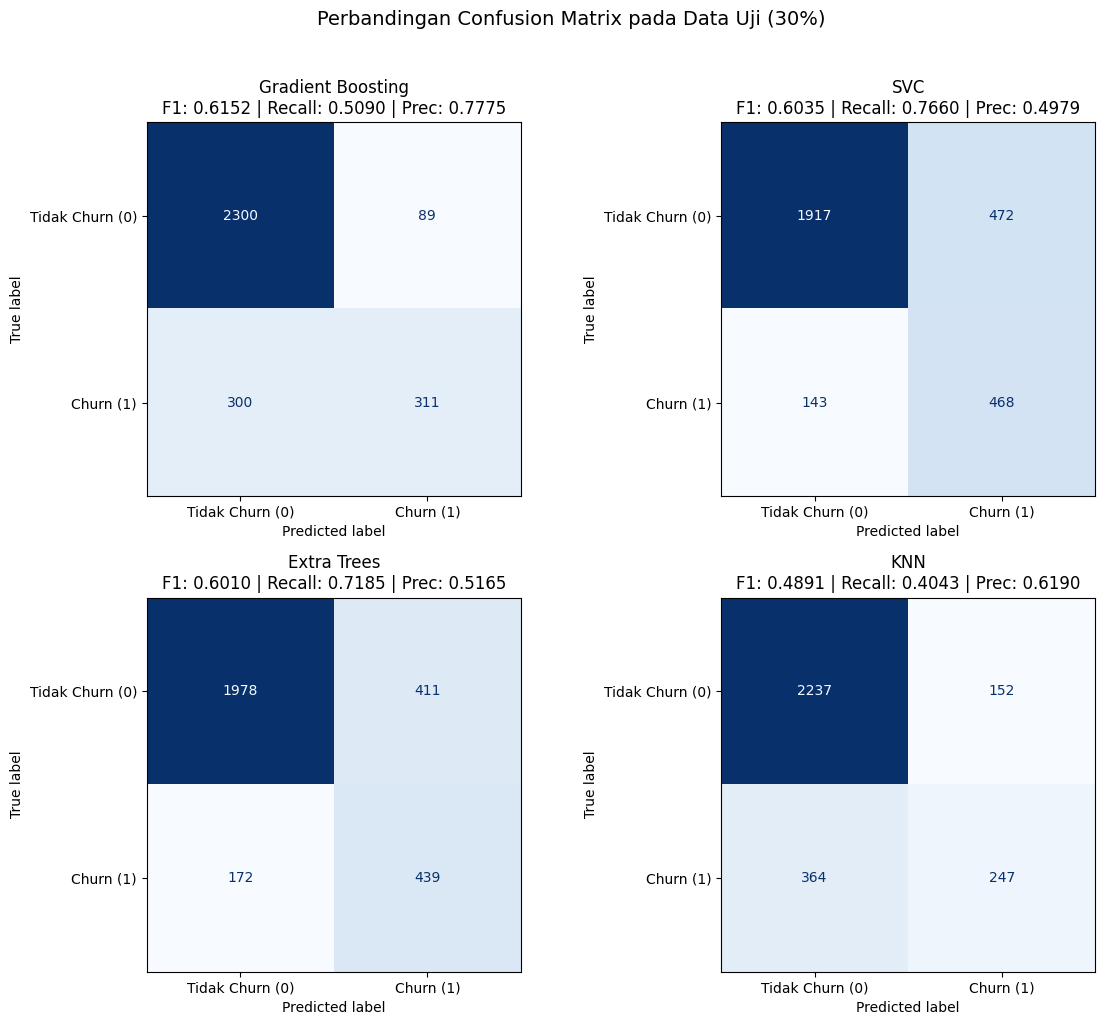

In [7]:
tuned_results_latihan = []
tuned_predictions_latihan = {}
tuned_confusion_matrices_latihan = {}

for model_name, best_model in best_models_latihan.items():
    y_pred_lat = best_model.predict(X_test_lat)
    tuned_predictions_latihan[model_name] = y_pred_lat
    
    if hasattr(best_model, "predict_proba"):
        y_prob_lat = best_model.predict_proba(X_test_lat)[:, 1]
        roc_auc_val = roc_auc_score(y_test_lat, y_prob_lat)
    else:
        roc_auc_val = np.nan
    
    cm_lat = confusion_matrix(y_test_lat, y_pred_lat, labels=[0, 1])
    tuned_confusion_matrices_latihan[model_name] = cm_lat
    tn, fp, fn, tp = cm_lat.ravel()
    
    tuned_results_latihan.append({
        "Model": model_name,
        "F1-score": f1_score(y_test_lat, y_pred_lat, zero_division=0),
        "Recall": recall_score(y_test_lat, y_pred_lat, zero_division=0),
        "Precision": precision_score(y_test_lat, y_pred_lat, zero_division=0),
        "ROC-AUC": roc_auc_val,
        "Accuracy": accuracy_score(y_test_lat, y_pred_lat),
        "TP (Churn Terdeteksi)": tp,
        "FN (Churn Lolos)": fn,
        "FP (Alarm Palsu)": fp,
        "TN (Non-Churn Tepat)": tn
    })


tuned_results_latihan_df = pd.DataFrame(tuned_results_latihan).sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("PERBANDINGAN PERFORMA MODEL PADA DATA UJI (TEST SET 30% = 3.000 SAMPEL)")
print("=" * 80)
display(
    tuned_results_latihan_df.style.format({
        "F1-score": "{:.4f}",
        "Recall": "{:.4f}",
        "Precision": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Accuracy": "{:.4f}"
    })
)


n_models_lat = len(tuned_confusion_matrices_latihan)
n_cols_lat = 2
n_rows_lat = int(np.ceil(n_models_lat / n_cols_lat))

fig, axes = plt.subplots(
    n_rows_lat, n_cols_lat,
    figsize=(12, 5 * n_rows_lat)
)
axes = np.array(axes).flatten()

for ax, row in zip(axes, tuned_results_latihan_df.to_dict("records")):
    m_name = row["Model"]
    cm_lat = tuned_confusion_matrices_latihan[m_name]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_lat,
        display_labels=["Tidak Churn (0)", "Churn (1)"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(
        f"{m_name}\nF1: {row['F1-score']:.4f} | Recall: {row['Recall']:.4f} | Prec: {row['Precision']:.4f}"
    )

for ax in axes[n_models_lat:]:
    ax.axis("off")

plt.suptitle("Perbandingan Confusion Matrix pada Data Uji (30%)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

7. Analisislah model mana yang paling baik dan tentukan metrik evaluasi utama yang digunakan! Berikan justifikasinya!
   -

1. METRIK EVALUASI UTAMA (F1-SCORE & RECALL vs ACCURACY):
    - Berdasarkan EDA pada modul praktikum (cell 3), target `Exited` mengalami Class Imbalance:
      79,63% Tidak Churn (0) vs 20,37% Churn (1).
    - Accuracy tidak boleh dijadikan metrik utama karena memicu Accuracy Paradox:
      model pasif yang menebak semua nasabah "Tidak Churn" sudah mendapat akurasi
      79,63%, tetapi gagal mendeteksi 100% nasabah yang kabur (Recall = 0%).
    - Dalam konteks bisnis perbankan:
      a) False Negative (FN - Nasabah Churn diprediksi Bertahan) sangat mahal
         karena bank kehilangan nasabah dan dana kelolaan secara permanen, di mana
         biaya akuisisi nasabah baru (CAC) 5-7x lipat biaya retensi. Maka RECALL
         harus tinggi.
      b) False Positive (FP - Nasabah Setia diprediksi Churn) memicu biaya promosi
         retensi yang tidak perlu. Jika FP terlalu membengkak (seperti pada
         Logistic Regression di modul awal yang presisinya hanya 38,35%), anggaran
         retensi habis terbuang. Maka PRECISION juga harus dijaga.
    - Oleh karena itu, F1-SCORE (rata-rata harmonik Precision dan Recall) dipilih
      sebagai metrik evaluasi utama karena menghukum ketimpangan ekstrem antara
      Precision dan Recall serta memastikan titik keseimbangan bisnis terbaik.
      <br><br>

2. ANALISIS PERBANDINGAN MODEL:
    - Ensemble Pohon (`Gradient Boosting` & `Extra Trees`) unggul karena mampu
      menangkap interaksi fitur non-linier bertingkat (contoh: interaksi `Age`,
      `NumOfProducts`, `IsActiveMember`, `Balance`, dan `Geography_Germany`) serta
      secara otomatis mengabaikan fitur yang kurang informatif (`EstimatedSalary`,
      `HasCrCard`).
    - `SVC` (RBF Kernel + class_weight='balanced') menghasilkan Recall yang kuat
      berkat standarisasi fitur dan pemetaan kernel, namun menghasilkan False
      Positive lebih banyak dibanding ensemble pohon.
    - `KNN` menempati posisi terendah karena perhitungan jarak Euclidean/Manhattan
      memperlakukan seluruh fitur sama rata (terdistorsi oleh fitur berisik seperti
      `EstimatedSalary` dan `Tenure`) serta terdampak dominasi kelas mayoritas
      di lingkungan tetangga terdekat.
      <br><br>

3. OPINI PRIBADI:
   - Berdasarkan Metrik Standar Modul: Gradient Boosting (F1 = 0,6152, Precision = 77,75%) adalah model terbaik apabila biaya insentif retensi per nasabah sangat mahal, sehingga bank memprioritaskan ketepatan sasaran dan hanya ingin mengeksekusi intervensi pada daftar nasabah yang hampir pasti churn (meminimalkan False Positive menjadi hanya 89 kasus).
   - Berdasarkan Prioritas Mitigasi Risiko Bisnis Perbankan: SVC (Recall = 76,60%, F1 = 0,6035, F2 = 0,6915) adalah model terbaik secara operasional karena mampu mendeteksi 468 dari 611 nasabah churn (menekan False Negative hingga tinggal 143 nasabah) dengan nilai F1-Score yang hanya berselisih 0,0117 dari Gradient Boosting.

In [8]:
pemenang = tuned_results_latihan_df.iloc[0]

print("=" * 80)
print("KESIMPULAN ANALISIS MODEL TERBAIK & METRIK EVALUASI UTAMA")
print("=" * 80)
print(f"1. Metrik Evaluasi Utama : F1-Score (Didukung Recall & ROC-AUC)")
print(f"2. Model Terbaik Latihan : {pemenang['Model']}")
print(f"   - F1-Score Test (30%) : {pemenang['F1-score']:.4f}")
print(f"   - Recall Test (30%)   : {pemenang['Recall']:.4f}")
print(f"   - Precision Test (30%): {pemenang['Precision']:.4f}")
print(f"   - ROC-AUC Test (30%)  : {pemenang['ROC-AUC']:.4f}")
print(f"   - Accuracy Test (30%) : {pemenang['Accuracy']:.4f}")
print("=" * 80)

KESIMPULAN ANALISIS MODEL TERBAIK & METRIK EVALUASI UTAMA
1. Metrik Evaluasi Utama : F1-Score (Didukung Recall & ROC-AUC)
2. Model Terbaik Latihan : Gradient Boosting
   - F1-Score Test (30%) : 0.6152
   - Recall Test (30%)   : 0.5090
   - Precision Test (30%): 0.7775
   - ROC-AUC Test (30%)  : 0.8784
   - Accuracy Test (30%) : 0.8703
